# Продажи и товарные потери FMCG

Анализ ассортимента за **октябрь–декабрь 2023 года**. Цель — оценить выручку и маржинальность, разделить SKU по ABC и выделить товары и категории для разбора потерь.

В исходном файле **40 020 строк, 500 SKU, 8 категорий и 100 магазинов**. Каждая строка содержит дату, магазин, товар, цены и количества. Анализ использует только `data/sales_data.csv`, который поставляется вместе с проектом.

Все расчёты выполняются последовательно через **Kernel → Restart Kernel and Run All Cells**. Достаточно Python 3.12+, `pandas`, `numpy`, `matplotlib`, `jinja2` и Jupyter. Сохранённые таблицы и графики доступны до запуска кода.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

%matplotlib inline


def find_project_root(start: Path) -> Path:
    """Находит ближайшую папку проекта по файлу data/sales_data.csv."""
    for folder in [start.resolve(), *start.resolve().parents]:
        if (folder / "data" / "sales_data.csv").is_file():
            return folder
    raise FileNotFoundError(
        "Не найден data/sales_data.csv. Распакуйте весь проект и запустите "
        "Jupyter из папки проекта или notebooks/."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
SOURCE = PROJECT_ROOT / "data" / "sales_data.csv"

COLORS = {"navy": "#19344C", "teal": "#2B7F7A", "slate": "#879BAB", "orange": "#B96B31"}
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 16,
    "axes.labelcolor": COLORS["navy"],
    "text.color": COLORS["navy"],
    "xtick.color": "#526576",
    "ytick.color": "#526576",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": "#D8E0E6",
    "grid.color": "#E6EBEF",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "figure.dpi": 130,
})


def fmt(value, digits=2):
    return f"{value:,.{digits}f}".replace(",", "\u202f").replace(".", ",")


def table(frame, formats=None):
    """Единое оформление небольших таблиц без изменения исходных чисел."""
    return (
        frame.style
        .hide(axis="index")
        .format(formats or {}, na_rep="—", thousands="\u202f", decimal=",")
        .set_table_styles([
            {"selector": "table", "props": [("border-collapse", "collapse"), ("font-size", "13px")]},
            {"selector": "th", "props": [("background", "#19344C"), ("color", "white"),
                ("padding", "10px 12px"), ("text-align", "left"), ("font-weight", "600")]},
            {"selector": "td", "props": [("padding", "9px 12px"), ("border-bottom", "1px solid #E3E9EE")]},
            {"selector": "tbody tr:nth-child(even)", "props": [("background", "#F4F7F9")]},
        ])
    )


display(Markdown(f"**Источник** — `{SOURCE.relative_to(PROJECT_ROOT).as_posix()}`."))

**Источник** — `data/sales_data.csv`.

## Загрузка и первичный обзор

Сначала читаем поля как строки. Это сохраняет идентификаторы и позволяет явно проверить преобразование чисел и дат. Исходный `raw` используется для контроля очистки.

In [2]:
LABELS = ["product_id", "product_name", "category", "store_id"]
PRICES = ["purchase_price", "selling_price"]
QUANTITIES = ["quantity_sold", "quantity_purchased", "losses"]
SOURCE_COLUMNS = [
    "product_id", "product_name", "category", *PRICES, *QUANTITIES, "date", "store_id"
]

raw = pd.read_csv(SOURCE, encoding="utf-8-sig", dtype="string", keep_default_na=False)
missing_columns = set(SOURCE_COLUMNS).difference(raw.columns)
if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {', '.join(sorted(missing_columns))}")
raw = raw[SOURCE_COLUMNS]

overview = pd.DataFrame({
    "Показатель": ["Строки", "SKU", "Категории", "Магазины", "Начало периода", "Конец периода"],
    "Значение": [
        fmt(len(raw), 0), fmt(raw.product_id.nunique(), 0), fmt(raw.category.nunique(), 0),
        fmt(raw.store_id.nunique(), 0), raw.date.min(), raw.date.max()
    ],
})
display(table(overview))
display(table(raw[["product_id", "category", "purchase_price", "selling_price", "date"]].head(4)))

Показатель,Значение
Строки,40 020
SKU,500
Категории,8
Магазины,100
Начало периода,2023-10-01
Конец периода,2023-12-31


product_id,category,purchase_price,selling_price,date
21,Хлебобулочные изделия,381.77,554.08,2023-11-22
12,Овощи,408.58,536.99,2023-11-08
248,Замороженные продукты,314.75,361.42,2023-11-07
129,Кондитерские изделия,314.34,393.28,2023-12-14


## Качество данных и очистка

Удаляем полные дубли. Преобразуем цены и количества в числа, дату — в `datetime`. Исключаем строки с отсутствующей, нечисловой или неположительной ценой, отрицательным количеством, дробным или отсутствующим количеством, пустыми идентификаторами и некорректной датой.

В задаче 1 отрицательные количества исключаются целыми строками. В задаче 2 Power Query обнуляет такие количества согласно её условию. Различие влияет на закупки и потери сохранённых строк.

In [3]:
prepared = raw.drop_duplicates().copy()
duplicate_count = len(raw) - len(prepared)

for column in LABELS + ["date"]:
    prepared[column] = prepared[column].str.strip()
for column in PRICES + QUANTITIES:
    prepared[column] = pd.to_numeric(prepared[column].str.strip(), errors="coerce").astype(float)
prepared["date"] = pd.to_datetime(prepared["date"], format="%Y-%m-%d", errors="coerce")

prices = prepared[PRICES]
quantities = prepared[QUANTITIES]
rules = {
    "Некорректная или отсутствующая цена": ((~np.isfinite(prices)) | prices.le(0)).any(axis=1),
    "Отрицательное количество": quantities.lt(0).any(axis=1),
    "Отсутствующее, нечисловое или дробное количество": (
        (~np.isfinite(quantities)) | quantities.mod(1).ne(0)
    ).any(axis=1),
    "Пустой идентификатор или категория": prepared[LABELS].eq("").any(axis=1),
    "Некорректная дата": prepared.date.isna(),
}

# Каждая исключённая строка получает первую причину. Сумма причин равна числу исключений.
exclusion_reason = pd.Series(pd.NA, index=prepared.index, dtype="string")
for reason, mask in rules.items():
    exclusion_reason.loc[mask & exclusion_reason.isna()] = reason

clean = prepared.loc[exclusion_reason.isna()].copy()
if clean.empty:
    raise ValueError("После очистки не осталось строк для анализа.")
clean[QUANTITIES] = clean[QUANTITIES].astype("int64")

metadata_counts = clean.groupby("product_id")[["product_name", "category"]].nunique()
if metadata_counts.gt(1).any().any():
    raise ValueError("Для одного product_id найдены разные названия или категории.")

quality = pd.DataFrame({
    "Причина исключения": ["Полные дубли", *rules],
    "Строки": [duplicate_count, *[int(exclusion_reason.eq(reason).sum()) for reason in rules]],
})
quality["Доля исходного файла, %"] = 100 * quality["Строки"] / len(raw)
display(table(quality, {"Строки": "{:,.0f}", "Доля исходного файла, %": "{:.3f}"}))

assert quality["Строки"].sum() + len(clean) == len(raw)
display(Markdown(
    f"После очистки осталось **{fmt(len(clean), 0)} строк**. "
    f"Исключено **{fmt(len(raw) - len(clean), 0)} строк** "
    f"({fmt(100 * (len(raw) - len(clean)) / len(raw))}% исходной выборки)."
))

Причина исключения,Строки,"Доля исходного файла, %"
Полные дубли,20,"0,050"
Некорректная или отсутствующая цена,100,"0,250"
Отрицательное количество,50,"0,125"
"Отсутствующее, нечисловое или дробное количество",0,"0,000"
Пустой идентификатор или категория,0,"0,000"
Некорректная дата,0,"0,000"


После очистки осталось **39 850 строк**. Исключено **170 строк** (0,42% исходной выборки).

In [4]:
diagnostics = pd.DataFrame({
    "Проверка": [
        "Повтор даты, магазина и SKU при отличии других полей",
        "Продано больше, чем закуплено в той же строке",
        "Потери выше закупленного количества",
        "Конфликты названия или категории внутри SKU",
    ],
    "Строки или SKU": [
        int(clean.duplicated(["date", "store_id", "product_id"]).sum()),
        int(clean.quantity_sold.gt(clean.quantity_purchased).sum()),
        int(clean.losses.gt(clean.quantity_purchased).sum()),
        int(metadata_counts.gt(1).any(axis=1).sum()),
    ],
})
display(table(diagnostics, {"Строки или SKU": "{:,.0f}"}))

Проверка,Строки или SKU
"Повтор даты, магазина и SKU при отличии других полей",180
"Продано больше, чем закуплено в той же строке",16 676
Потери выше закупленного количества,0
Конфликты названия или категории внутри SKU,0


180 повторов сочетания «дата — магазин — SKU» сохранены, поскольку записи отличаются другими значениями, а ключ операции отсутствует. В 16 676 строках продажи выше закупок. Начальные остатки не представлены, поэтому такой случай допускает продажу ранее закупленного товара.

В папке задания `sales_data1.csv` побайтно совпадает с исходным CSV. Файлы `stage*.csv` содержат промежуточные результаты. В расчёты входит один исходный файл.

## Метрики по SKU и категориям

Валовая прибыль рассчитывается до списаний. Потери в рублях оцениваются по закупочной цене соответствующей строки. Для агрегированных процентов сначала суммируем числители и знаменатели.

| Показатель | Расчёт за выбранную группу |
| --- | --- |
| Выручка | Σ(продано × цена продажи) |
| Валовая прибыль | Выручка − Σ(продано × цена закупки) |
| Gross margin, % | Валовая прибыль / Выручка × 100 |
| Markup, % | Валовая прибыль / Себестоимость проданного × 100 |
| Losses rate, % | ΣПотери, шт. / ΣЗакуплено, шт. × 100 |
| Потери, ₽ | Σ(потери × цена закупки) |
| Inventory turnover | ΣПродано / ((ΣЗакуплено + ΣПотери) / 2) |

`Inventory turnover` использует формулу задания. Для расчёта по среднему фактическому запасу нужны остатки. Нулевой знаменатель даёт `NaN`. В Python-таблицах процент `9.07` означает 9,07%.

In [5]:
MONEY = ["revenue", "cogs", "gross_profit", "purchase_value", "losses_value"]
MEASURES = [*QUANTITIES, *MONEY]


def divide(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """Оставляет метрику неопределённой при нулевом знаменателе."""
    return numerator.div(denominator.where(denominator.ne(0)))


def add_measures(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    result["revenue"] = result.quantity_sold * result.selling_price
    result["cogs"] = result.quantity_sold * result.purchase_price
    result["gross_profit"] = result.revenue - result.cogs
    result["purchase_value"] = result.quantity_purchased * result.purchase_price
    result["losses_value"] = result.losses * result.purchase_price
    return result


def add_ratios(totals: pd.DataFrame) -> pd.DataFrame:
    result = totals.copy()
    result["gross_margin_pct"] = 100 * divide(result.gross_profit, result.revenue)
    result["markup_pct"] = 100 * divide(result.gross_profit, result.cogs)
    result["losses_rate_pct"] = 100 * divide(result.losses, result.quantity_purchased)
    result["losses_value_rate_pct"] = 100 * divide(result.losses_value, result.purchase_value)
    stock_proxy = (result.quantity_purchased + result.losses) / 2
    result["turnover"] = divide(result.quantity_sold, stock_proxy)
    return result


def aggregate(frame: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    totals = frame.groupby(by, as_index=False, sort=False)[MEASURES].sum()
    return add_ratios(totals)


rows = add_measures(clean)
products = aggregate(rows, ["product_id", "product_name", "category"])
categories = aggregate(rows, ["category"]).sort_values(
    ["revenue", "category"], ascending=[False, True]
)
overall = add_ratios(rows[MEASURES].sum().to_frame().T).iloc[0]

In [6]:
headline = pd.DataFrame({
    "Показатель за весь период": [
        "Выручка, ₽", "Валовая прибыль до списаний, ₽", "Gross margin, %",
        "Markup, %", "Потери по закупочной цене, ₽", "Losses rate по штукам, %",
        "Потери от стоимости закупок, %", "Inventory turnover, раз",
    ],
    "Значение": [
        fmt(overall.revenue), fmt(overall.gross_profit), fmt(overall.gross_margin_pct),
        fmt(overall.markup_pct), fmt(overall.losses_value), fmt(overall.losses_rate_pct),
        fmt(overall.losses_value_rate_pct), fmt(overall.turnover, 3),
    ],
})
display(table(headline))

category_view = categories[[
    "category", "revenue", "gross_margin_pct", "markup_pct", "losses_value", "losses_rate_pct", "turnover"
]].rename(columns={
    "category": "Категория", "revenue": "Выручка, ₽", "gross_margin_pct": "Маржа, %",
    "markup_pct": "Наценка, %", "losses_value": "Потери, ₽",
    "losses_rate_pct": "Потери, % шт.", "turnover": "Turnover",
})
display(table(category_view, {
    "Выручка, ₽": "{:,.2f}", "Маржа, %": "{:.2f}", "Наценка, %": "{:.2f}",
    "Потери, ₽": "{:,.2f}", "Потери, % шт.": "{:.2f}", "Turnover": "{:.3f}",
}))

Показатель за весь период,Значение
"Выручка, ₽","6 770 833 903,39"
"Валовая прибыль до списаний, ₽","1 561 416 442,74"
"Gross margin, %","23,06"
"Markup, %","29,97"
"Потери по закупочной цене, ₽","546 337 470,04"
"Losses rate по штукам, %","9,07"
"Потери от стоимости закупок, %","9,07"
"Inventory turnover, раз","1,587"


Категория,"Выручка, ₽","Маржа, %","Наценка, %","Потери, ₽","Потери, % шт.",Turnover
Хлебобулочные изделия,"991 455 095,69","23,31","30,39","79 392 526,74","8,99","1,580"
Кондитерские изделия,"926 199 048,66","23,05","29,96","74 223 694,74","8,90","1,579"
Напитки,"920 660 533,63","22,99","29,85","74 512 807,50","9,06","1,583"
Овощи,"830 163 330,75","23,09","30,03","66 905 037,69","9,19","1,604"
Мясо,"807 822 102,35","23,26","30,31","64 582 825,45","9,16","1,607"
Бакалея,"788 581 696,19","22,89","29,69","63 047 222,47","9,04","1,595"
Молочные продукты,"757 050 129,69","22,80","29,54","61 872 078,94","9,04","1,576"
Замороженные продукты,"748 901 966,43","23,02","29,90","61 801 276,51","9,22","1,578"


## ABC-анализ по выручке

Сортируем SKU по убыванию выручки. При равной выручке используем `product_id` для воспроизводимого порядка. Класс A закрывает первые 80% выручки, B — следующие 15%, C — оставшиеся 5%. Товар, пересекающий порог, включается в класс, который закрывает эту границу. Поэтому итоговые доли могут немного отличаться от 80 / 15 / 5.

In [7]:
def classify_abc(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    ranked = frame.sort_values(["revenue", "product_id"], ascending=[False, True]).copy()
    revenue_total = ranked.revenue.sum()
    ranked["revenue_share_pct"] = np.nan
    ranked["cum_revenue_share_pct"] = np.nan
    ranked["abc_class"] = pd.Series(pd.NA, index=ranked.index, dtype="string")
    if revenue_total > 0:
        ranked["revenue_share_pct"] = 100 * ranked.revenue / revenue_total
        ranked["cum_revenue_share_pct"] = 100 * ranked.revenue.cumsum() / revenue_total
        previous_share = ranked.cum_revenue_share_pct.shift(fill_value=0).round(10)
        ranked["abc_class"] = np.select(
            [previous_share.lt(80), previous_share.lt(95)], ["A", "B"], "C"
        )
    classes = ranked.groupby("abc_class").revenue.agg(sku_count="size", revenue="sum")
    classes = classes.reindex(["A", "B", "C"], fill_value=0).reset_index()
    classes["revenue_share_pct"] = (
        100 * classes.revenue / revenue_total if revenue_total > 0 else np.nan
    )
    return ranked.reset_index(drop=True), classes


products, abc_summary = classify_abc(products)
abc_view = abc_summary.assign(sku_share_pct=100 * abc_summary.sku_count / len(products)).rename(columns={
    "abc_class": "Класс", "sku_count": "SKU", "sku_share_pct": "Доля SKU, %",
    "revenue": "Выручка, ₽", "revenue_share_pct": "Доля выручки, %",
})[["Класс", "SKU", "Доля SKU, %", "Выручка, ₽", "Доля выручки, %"]]
display(table(abc_view, {"SKU": "{:,.0f}", "Доля SKU, %": "{:.1f}",
    "Выручка, ₽": "{:,.2f}", "Доля выручки, %": "{:.2f}"}))

Класс,SKU,"Доля SKU, %","Выручка, ₽","Доля выручки, %"
A,378,"75,6","5 419 462 268,61","80,04"
B,89,"17,8","1 022 308 832,59","15,10"
C,33,"6,6","329 062 802,19","4,86"


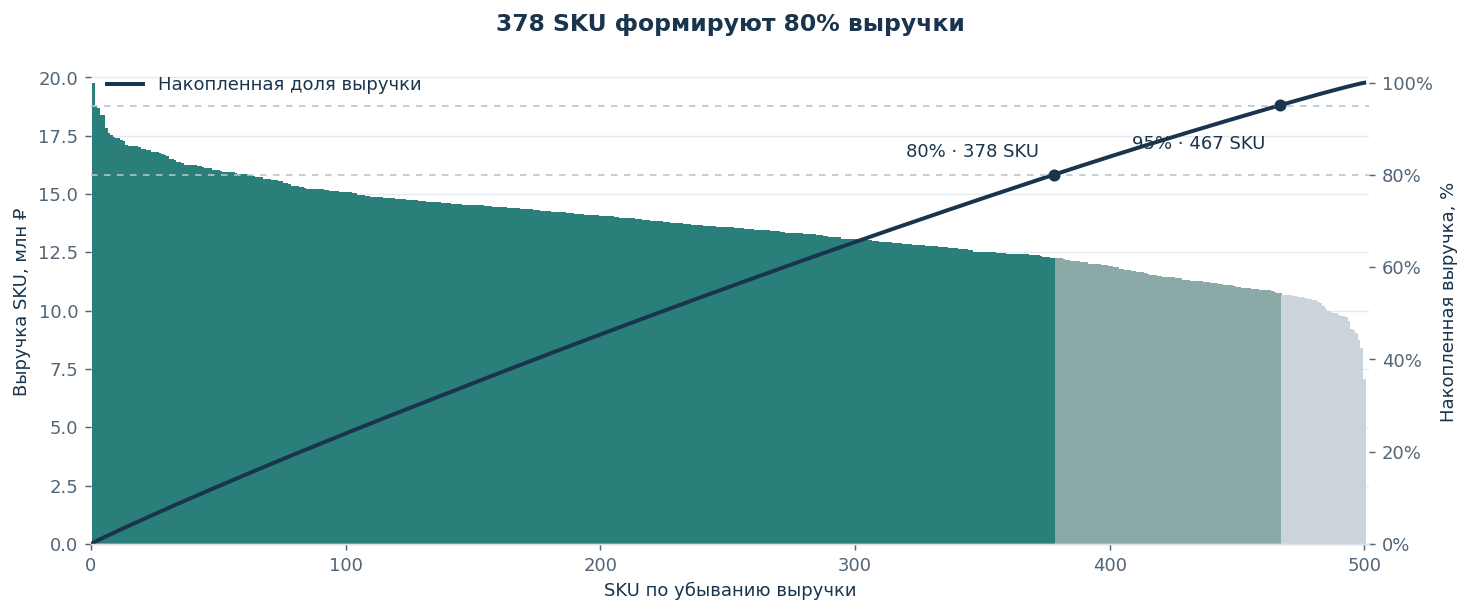

In [8]:
rank = np.arange(1, len(products) + 1)
class_colors = {"A": COLORS["teal"], "B": "#8BAAA7", "C": "#CBD4DA"}
fig, ax = plt.subplots(figsize=(11.2, 4.6), layout="constrained")
ax.bar(rank, products.revenue / 1e6,
       color=products.abc_class.map(class_colors), width=1.05, linewidth=0)
ax.set(xlabel="SKU по убыванию выручки", ylabel="Выручка SKU, млн ₽", xlim=(0, len(products) + 2))
a_count = int(abc_summary.loc[abc_summary.abc_class.eq("A"), "sku_count"].iloc[0])
ax.set_title(f"{a_count} SKU формируют 80% выручки")
ax.grid(axis="y", zorder=0)
ax.set_axisbelow(True)
curve = ax.twinx()
curve.plot(np.r_[0, rank], np.r_[0, products.cum_revenue_share_pct],
           color=COLORS["navy"], linewidth=2.2, label="Накопленная доля выручки")
curve.set(ylabel="Накопленная выручка, %", ylim=(0, 105))
curve.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
for threshold in [80, 95]:
    boundary = int(products.cum_revenue_share_pct.ge(threshold).to_numpy().argmax()) + 1
    curve.axhline(threshold, color="#B7C4CE", linewidth=0.9, linestyle=(0, (4, 4)))
    curve.scatter(boundary, products.iloc[boundary - 1].cum_revenue_share_pct,
                  s=32, color=COLORS["navy"], zorder=5)
    curve.annotate(f"{threshold}% · {boundary} SKU",
                   (boundary, products.iloc[boundary - 1].cum_revenue_share_pct),
                   xytext=(-8, -24 if threshold == 95 else 10), textcoords="offset points",
                   ha="right", fontsize=10, color=COLORS["navy"])
curve.legend(frameon=False, loc="upper left")
plt.show()

На класс A приходится **378 SKU из 500**, или **75,6% ассортимента**. Выручка распределена между многими товарами. Для анализа потерь внутри A полезно дополнительно ранжировать SKU по сумме списаний.

## Категории с наибольшими потерями

Две пятёрки отвечают на разные вопросы. Сумма в рублях показывает масштаб потерь, а доля в штуках — интенсивность потерь относительно закупленного количества. Для каждой пятёрки сохраняем оба показателя.

In [9]:
top_losses_rub = categories.sort_values(["losses_value", "category"], ascending=[False, True]).head(5)
top_losses_pct = categories.sort_values(["losses_rate_pct", "category"], ascending=[False, True]).head(5)


def show_losses(frame):
    view = frame[["category", "losses_value", "losses_rate_pct"]].rename(columns={
        "category": "Категория", "losses_value": "Потери, ₽", "losses_rate_pct": "Потери, % шт."
    })
    return table(view, {"Потери, ₽": "{:,.2f}", "Потери, % шт.": "{:.2f}"})


display(Markdown("**Топ-5 по сумме потерь**"))
display(show_losses(top_losses_rub))
display(Markdown("**Топ-5 по доле потерь в штуках**"))
display(show_losses(top_losses_pct))

**Топ-5 по сумме потерь**

Категория,"Потери, ₽","Потери, % шт."
Хлебобулочные изделия,"79 392 526,74","8,99"
Напитки,"74 512 807,50","9,06"
Кондитерские изделия,"74 223 694,74","8,90"
Овощи,"66 905 037,69","9,19"
Мясо,"64 582 825,45","9,16"


**Топ-5 по доле потерь в штуках**

Категория,"Потери, ₽","Потери, % шт."
Замороженные продукты,"61 801 276,51","9,22"
Овощи,"66 905 037,69","9,19"
Мясо,"64 582 825,45","9,16"
Напитки,"74 512 807,50","9,06"
Молочные продукты,"61 872 078,94","9,04"


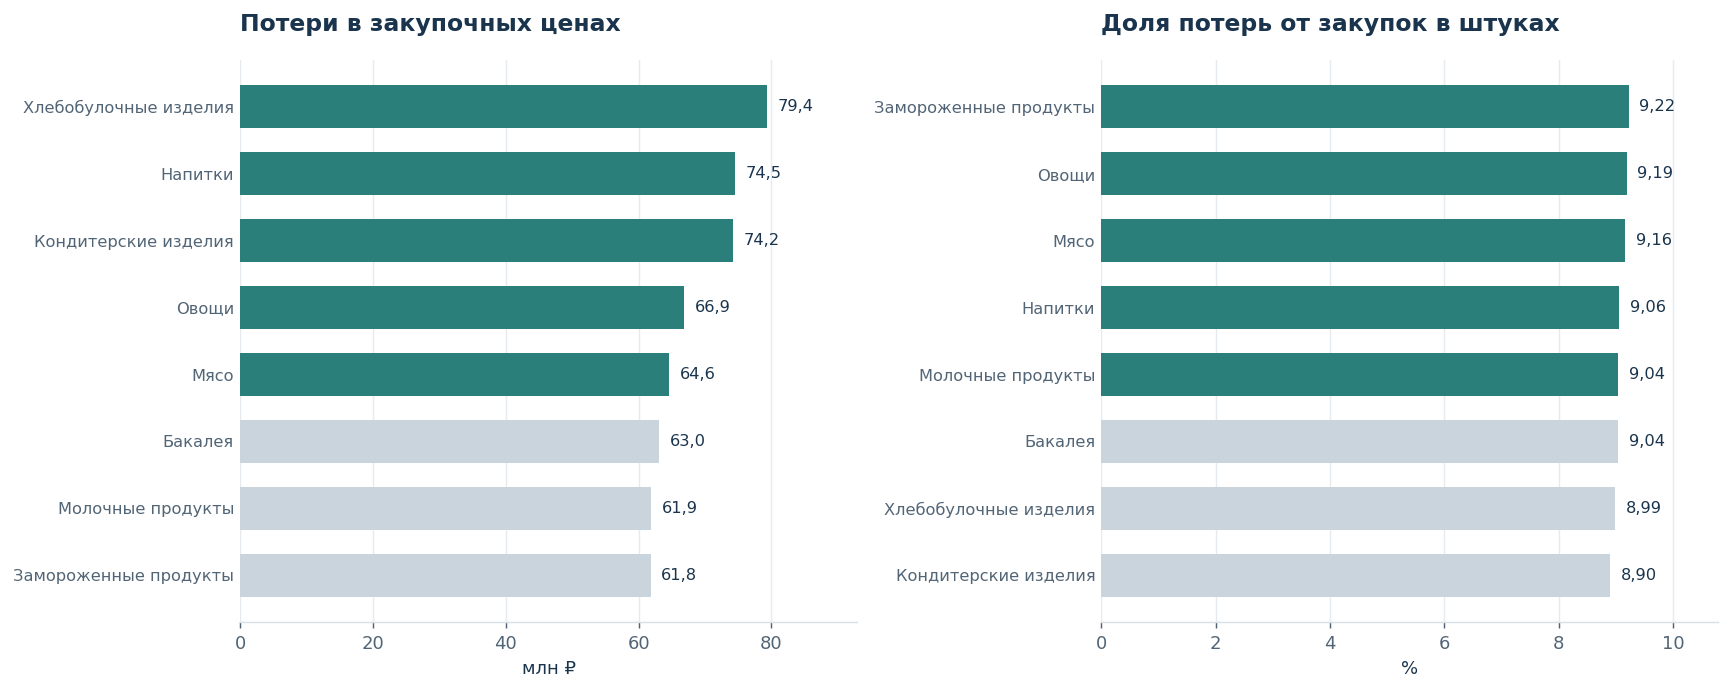

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), layout="constrained")
specs = [
    (axes[0], "losses_value", 1e6, "Потери в закупочных ценах", "млн ₽", "{:.1f}"),
    (axes[1], "losses_rate_pct", 1, "Доля потерь от закупок в штуках", "%", "{:.2f}"),
]
for axis, column, divisor, title, unit, value_format in specs:
    ordered = categories.sort_values(column, ascending=False)
    values = ordered[column] / divisor
    axis.barh(ordered.category, values,
              color=[COLORS["teal"]] * 5 + ["#C9D4DC"] * 3, height=0.64)
    axis.invert_yaxis()
    axis.set_title(title, loc="left")
    axis.set_xlabel(unit)
    axis.set_xlim(0, values.max() * 1.17)
    axis.grid(axis="x")
    axis.set_axisbelow(True)
    axis.tick_params(axis="y", length=0, labelsize=9)
    for y, value in enumerate(values):
        axis.text(value + values.max() * 0.02, y,
                  value_format.format(value).replace(".", ","), va="center", fontsize=9)
plt.show()

In [11]:
largest_value = top_losses_rub.iloc[0]
largest_rate = top_losses_pct.iloc[0]
top_five_share = 100 * top_losses_rub.losses_value.sum() / overall.losses_value
display(Markdown(
    f"**{largest_value.category}** дают максимальную сумму потерь — "
    f"**{fmt(largest_value.losses_value / 1e6, 1)} млн ₽**, "
    f"при доле потерь {fmt(largest_value.losses_rate_pct)}% в штуках. "
    f"Самая высокая доля у категории **«{largest_rate.category}» — "
    f"{fmt(largest_rate.losses_rate_pct)}%**. "
    f"Пять категорий с наибольшей суммой формируют {fmt(top_five_share, 1)}% всех потерь в рублях."
))

**Хлебобулочные изделия** дают максимальную сумму потерь — **79,4 млн ₽**, при доле потерь 8,99% в штуках. Самая высокая доля у категории **«Замороженные продукты» — 9,22%**. Пять категорий с наибольшей суммой формируют 65,8% всех потерь в рублях.

## Товары с потерями выше 8% и выручкой выше 500 тыс. ₽

Условия применяются строго по формулировке задания — `losses_rate_pct > 8` и `revenue > 500_000`. Полный отбор остаётся в `flagged_products`. Для первого разбора выбираем внутри отбора класс A и сортируем по убыванию потерь в рублях.

In [12]:
LOSS_RATE_THRESHOLD = 8.0
REVENUE_THRESHOLD = 500_000
TURNOVER_THRESHOLD = 1.5

flagged_products = products.loc[
    products.losses_rate_pct.gt(LOSS_RATE_THRESHOLD) & products.revenue.gt(REVENUE_THRESHOLD)
].sort_values(["losses_rate_pct", "revenue", "product_id"], ascending=[False, False, True]).copy()

priority_a = flagged_products.loc[flagged_products.abc_class.eq("A")].sort_values(
    ["losses_value", "product_id"], ascending=[False, True]
)
flagged_summary = pd.DataFrame({
    "Группа": ["Все товары в отборе", "Из них класс A"],
    "SKU": [len(flagged_products), len(priority_a)],
    "Выручка, ₽": [flagged_products.revenue.sum(), priority_a.revenue.sum()],
    "Потери, ₽": [flagged_products.losses_value.sum(), priority_a.losses_value.sum()],
    "Доля всех потерь, %": [
        100 * flagged_products.losses_value.sum() / overall.losses_value,
        100 * priority_a.losses_value.sum() / overall.losses_value,
    ],
})
display(table(flagged_summary, {"SKU": "{:,.0f}", "Выручка, ₽": "{:,.2f}",
    "Потери, ₽": "{:,.2f}", "Доля всех потерь, %": "{:.2f}"}))

priority_view = priority_a.head(10)[[
    "product_name", "category", "revenue", "losses_value", "losses_rate_pct", "abc_class"
]].rename(columns={
    "product_name": "Товар", "category": "Категория", "revenue": "Выручка, ₽",
    "losses_value": "Потери, ₽", "losses_rate_pct": "Потери, % шт.", "abc_class": "ABC",
})
display(table(priority_view, {"Выручка, ₽": "{:,.2f}", "Потери, ₽": "{:,.2f}", "Потери, % шт.": "{:.2f}"}))

Группа,SKU,"Выручка, ₽","Потери, ₽","Доля всех потерь, %"
Все товары в отборе,460,"6 235 662 562,76","507 387 243,16","92,87"
Из них класс A,348,"4 997 123 563,42","401 370 097,38","73,47"


Товар,Категория,"Выручка, ₽","Потери, ₽","Потери, % шт.",ABC
Товар_162,Овощи,"19 768 606,33","1 727 611,42","10,52",A
Товар_401,Напитки,"18 371 057,24","1 575 641,32","9,35",A
Товар_249,Кондитерские изделия,"16 251 425,67","1 486 739,61","10,81",A
Товар_402,Напитки,"16 999 617,54","1 477 349,10","8,69",A
Товар_90,Бакалея,"18 407 437,48","1 472 336,81","9,37",A
Товар_370,Кондитерские изделия,"17 846 513,49","1 455 166,19","8,71",A
Товар_105,Мясо,"16 259 908,28","1 432 360,79","9,37",A
Товар_455,Замороженные продукты,"13 694 507,18","1 422 931,22","10,98",A
Товар_461,Замороженные продукты,"16 458 448,84","1 416 095,08","9,58",A
Товар_112,Замороженные продукты,"16 508 504,80","1 413 051,07","9,55",A


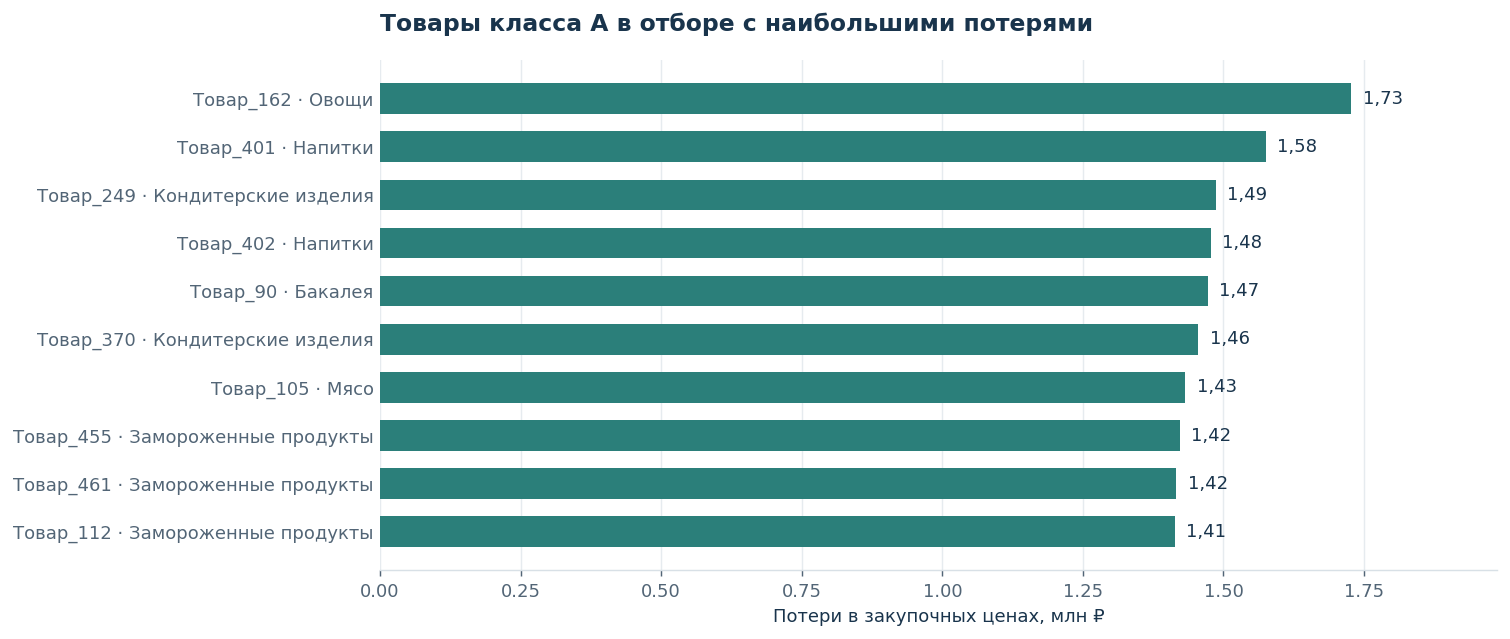

In [13]:
top_priority = priority_a.head(10).copy()
labels = top_priority.product_name + " · " + top_priority.category
fig, ax = plt.subplots(figsize=(11.5, 4.8), layout="constrained")
values = top_priority.losses_value / 1e6
ax.barh(labels, values, color=COLORS["teal"], height=0.64)
ax.invert_yaxis()
ax.set_title("Товары класса A в отборе с наибольшими потерями", loc="left")
ax.set_xlabel("Потери в закупочных ценах, млн ₽")
ax.set_xlim(0, values.max() * 1.15)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
ax.set_axisbelow(True)
for y, value in enumerate(values):
    ax.text(value + 0.02, y, fmt(value, 2), va="center", fontsize=10)
plt.show()

In [14]:
first_priority = priority_a.iloc[0]
display(Markdown(
    f"Порог выделяет **{len(flagged_products)} из {len(products)} SKU** "
    f"({fmt(100 * len(flagged_products) / len(products), 0)}% ассортимента). "
    f"Внутри отбора **{len(priority_a)} SKU класса A** дают "
    f"**{fmt(priority_a.losses_value.sum() / 1e6, 1)} млн ₽ потерь**, "
    f"или {fmt(100 * priority_a.losses_value.sum() / overall.losses_value, 1)}% общей суммы. "
    f"Первым в этой группе стоит **{first_priority.product_name}** "
    f"из категории «{first_priority.category}» — {fmt(first_priority.losses_value / 1e6)} млн ₽, "
    f"потери {fmt(first_priority.losses_rate_pct)}% в штуках."
))

Порог выделяет **460 из 500 SKU** (92% ассортимента). Внутри отбора **348 SKU класса A** дают **401,4 млн ₽ потерь**, или 73,5% общей суммы. Первым в этой группе стоит **Товар_162** из категории «Овощи» — 1,73 млн ₽, потери 10,52% в штуках.

## Категории с turnover ниже 1,5

Проверяем заданный порог на агрегированных количествах каждой категории за весь период.

In [15]:
turnover_view = categories[["category", "turnover"]].sort_values(["turnover", "category"])
low_turnover_categories = categories.loc[categories.turnover.lt(TURNOVER_THRESHOLD)].sort_values(
    ["turnover", "category"]
)
display(table(turnover_view.rename(columns={"category": "Категория", "turnover": "Turnover"}),
              {"Turnover": "{:.3f}"}))

minimum = turnover_view.iloc[0]
display(Markdown(
    f"Категорий ниже порога 1,5 — **{len(low_turnover_categories)}**. "
    f"Минимальное значение у категории «{minimum.category}» — **{fmt(minimum.turnover, 3)}**."
))

Категория,Turnover
Молочные продукты,"1,576"
Замороженные продукты,"1,578"
Кондитерские изделия,"1,579"
Хлебобулочные изделия,"1,580"
Напитки,"1,583"
Бакалея,"1,595"
Овощи,"1,604"
Мясо,"1,607"


Категорий ниже порога 1,5 — **0**. Минимальное значение у категории «Молочные продукты» — **1,576**.

## Контроль расчётов

Сверяем суммы по товарам и категориям с очищенными строками, а денежные итоги дополнительно пересчитываем в целых копейках. Это проверяет группировку и влияние вычислений с плавающей точкой.

In [16]:
for frame in [products, categories]:
    for column in MEASURES:
        np.testing.assert_allclose(frame[column].sum(), rows[column].sum(), rtol=0, atol=0.01)

purchase_kopecks = (clean.purchase_price * 100).round().astype("int64")
selling_kopecks = (clean.selling_price * 100).round().astype("int64")
independent_money = {
    "revenue": int((clean.quantity_sold * selling_kopecks).sum()),
    "cogs": int((clean.quantity_sold * purchase_kopecks).sum()),
    "purchase_value": int((clean.quantity_purchased * purchase_kopecks).sum()),
    "losses_value": int((clean.losses * purchase_kopecks).sum()),
}
for column, kopecks in independent_money.items():
    assert round(float(overall[column]) * 100) == kopecks, column

assert products.product_id.is_unique
assert len(products) == clean.product_id.nunique()
assert len(categories) == clean.category.nunique()
assert abc_summary.sku_count.sum() == len(products)
assert set(flagged_products.product_id).issubset(set(products.product_id))

control = pd.DataFrame({
    "Проверка": ["Количество строк после очистки", "Выручка в копейках", "Потери в копейках",
                 "Суммы по SKU и категориям", "Уникальность SKU и полнота ABC"],
    "Результат": [fmt(len(clean), 0), str(independent_money["revenue"]),
                  str(independent_money["losses_value"]), "Совпадают с суммами строк", "Проверено"],
})
display(table(control))

Проверка,Результат
Количество строк после очистки,39 850
Выручка в копейках,677083390339
Потери в копейках,54633747004
Суммы по SKU и категориям,Совпадают с суммами строк
Уникальность SKU и полнота ABC,Проверено


## Выводы для разбора с бизнесом

- За октябрь–декабрь выручка составила **6,77 млрд ₽**, валовая маржа — **23,06%**, потери в закупочных ценах — **546,34 млн ₽**. Доля потерь в штуках составила **9,07%**.
- У хлебобулочных изделий максимальная сумма потерь — **79,39 млн ₽**. У замороженных продуктов максимальная доля потерь — **9,22%** в штуках. Эти категории задают два направления разбора — вклад в общую сумму и относительный уровень потерь.
- **460 SKU** проходят заданный отбор. Для первого разбора можно использовать **348 товаров класса A**, которые формируют **401,37 млн ₽**, или **73,5%**, всех потерь. Внутри группы первым по сумме стоит `Товар_162` из категории «Овощи».
- Категорий с `turnover < 1.5` не обнаружено. Минимум составляет **1,576** у молочных продуктов.

Чтобы установить причины списаний, к выбранным SKU нужны данные о сроках годности, причинах списания, промо и остатках по магазинам. По представленному набору можно определить масштаб потерь и порядок разбора.

## Выгрузка результатов

Следующая ячейка обновляет CSV в `results/pandas/` и краткую сводку `summary.json`. Деньги сохраняются с точностью до копейки, проценты — в процентных пунктах. Полный список отобранных товаров доступен в `flagged_products.csv`.

In [17]:
OUTPUT_DIR = PROJECT_ROOT / "results" / "pandas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

reports = {
    "product_summary": products,
    "category_summary": categories,
    "abc_summary": abc_summary,
    "top_losses_rub": top_losses_rub,
    "top_losses_pct": top_losses_pct,
    "flagged_products": flagged_products,
    "low_turnover_categories": low_turnover_categories,
}
for name, report in reports.items():
    export = report.copy()
    for column in report.columns.intersection(MONEY):
        export[column] = report[column].map("{:.2f}".format)
    export.to_csv(OUTPUT_DIR / f"{name}.csv", encoding="utf-8-sig", index=False, float_format="%.8f")

summary = {
    "source_file": "sales_data.csv",
    "date_min": clean.date.min().strftime("%Y-%m-%d"),
    "date_max": clean.date.max().strftime("%Y-%m-%d"),
    "input_rows": len(raw), "clean_rows": len(clean),
    "sku_count": len(products), "category_count": len(categories),
    "store_count": int(clean.store_id.nunique()),
    "flagged_sku_count": len(flagged_products),
    "priority_a_sku_count": len(priority_a),
    "low_turnover_category_count": len(low_turnover_categories),
    "thresholds": {"losses_rate_pct_gt": LOSS_RATE_THRESHOLD,
                   "revenue_gt": REVENUE_THRESHOLD, "turnover_lt": TURNOVER_THRESHOLD},
    "cleaning": {
        "input_rows": len(raw), "exact_duplicate_rows": duplicate_count,
        "missing_or_nonnumeric_price_rows": int(prices.isna().any(axis=1).sum()),
        "invalid_price_rows": int(rules["Некорректная или отсутствующая цена"].sum()),
        "negative_quantity_rows": int(rules["Отрицательное количество"].sum()),
        "missing_or_invalid_quantity_rows": int(
            rules["Отсутствующее, нечисловое или дробное количество"].sum()
        ),
        "invalid_label_rows": int(rules["Пустой идентификатор или категория"].sum()),
        "invalid_date_rows": int(rules["Некорректная дата"].sum()),
        "invalid_rows_after_deduplication": int(exclusion_reason.notna().sum()),
        "clean_rows": len(clean), "removed_rows": len(raw) - len(clean),
        "retained_repeated_date_store_product_rows": int(
            clean.duplicated(["date", "store_id", "product_id"]).sum()
        ),
        "sold_above_purchased_rows": int(clean.quantity_sold.gt(clean.quantity_purchased).sum()),
        "losses_above_purchased_rows": int(clean.losses.gt(clean.quantity_purchased).sum()),
    },
    "totals": {
        **{column: int(overall[column]) for column in QUANTITIES},
        **{column: round(float(overall[column]), 2) for column in MONEY},
        **{column: None if pd.isna(overall[column]) else float(overall[column])
           for column in overall.index.difference(MEASURES)},
    },
}
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
display(Markdown(f"Созданы **7 CSV и summary.json** в `{OUTPUT_DIR.relative_to(PROJECT_ROOT).as_posix()}/`."))

Созданы **7 CSV и summary.json** в `results/pandas/`.